* What it means to "freeze" weights
* How to freeze weights in PyTorch
* Why and when freezing weights might be helpful

# Intro

* "Freezing weights": Preventing gradient descent from adjusting the parameters
* Its used to train only certain layers during fine-tuning. Common in computer vision or with small datasets
* Freezing weights decreases computation time and makes model adjustments more subtle.
* Trainability is set by the requires_grad parameter in a PyTorch tensor

# Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer
import requests

In [2]:
# load pretrained GPT-2 model and tokenizer
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [3]:
# hyperparameters
seq_len    = 256 # max sequence length
batch_size = 16

# use GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [4]:
# tokenize Gulliver's travels
text = requests.get('https://www.gutenberg.org/cache/epub/829/pg829.txt').text
gtTokens = tokenizer.encode(text, return_tensors='pt')[0]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (158340 > 1024). Running this sequence through the model will result in indexing errors


# Freeze all attention head weights

In [5]:
for name, param in gpt2.named_parameters():
  print(name)

transformer.wte.weight
transformer.wpe.weight
transformer.h.0.ln_1.weight
transformer.h.0.ln_1.bias
transformer.h.0.attn.c_attn.weight
transformer.h.0.attn.c_attn.bias
transformer.h.0.attn.c_proj.weight
transformer.h.0.attn.c_proj.bias
transformer.h.0.ln_2.weight
transformer.h.0.ln_2.bias
transformer.h.0.mlp.c_fc.weight
transformer.h.0.mlp.c_fc.bias
transformer.h.0.mlp.c_proj.weight
transformer.h.0.mlp.c_proj.bias
transformer.h.1.ln_1.weight
transformer.h.1.ln_1.bias
transformer.h.1.attn.c_attn.weight
transformer.h.1.attn.c_attn.bias
transformer.h.1.attn.c_proj.weight
transformer.h.1.attn.c_proj.bias
transformer.h.1.ln_2.weight
transformer.h.1.ln_2.bias
transformer.h.1.mlp.c_fc.weight
transformer.h.1.mlp.c_fc.bias
transformer.h.1.mlp.c_proj.weight
transformer.h.1.mlp.c_proj.bias
transformer.h.2.ln_1.weight
transformer.h.2.ln_1.bias
transformer.h.2.attn.c_attn.weight
transformer.h.2.attn.c_attn.bias
transformer.h.2.attn.c_proj.weight
transformer.h.2.attn.c_proj.bias
transformer.h.2.ln_2

In [6]:
for name, param in gpt2.named_parameters():
  if '.h' in name:
    param.requires_grad = False
    print(f'--- Layer {name} is frozen (.requres_grad = {param.requires_grad}).')

  elif '.h.' not in name:
    print(f'+++ Layer {name} is trainable (.requires_grad = {param.requires_grad}).')

+++ Layer transformer.wte.weight is trainable (.requires_grad = True).
+++ Layer transformer.wpe.weight is trainable (.requires_grad = True).
--- Layer transformer.h.0.ln_1.weight is frozen (.requres_grad = False).
--- Layer transformer.h.0.ln_1.bias is frozen (.requres_grad = False).
--- Layer transformer.h.0.attn.c_attn.weight is frozen (.requres_grad = False).
--- Layer transformer.h.0.attn.c_attn.bias is frozen (.requres_grad = False).
--- Layer transformer.h.0.attn.c_proj.weight is frozen (.requres_grad = False).
--- Layer transformer.h.0.attn.c_proj.bias is frozen (.requres_grad = False).
--- Layer transformer.h.0.ln_2.weight is frozen (.requres_grad = False).
--- Layer transformer.h.0.ln_2.bias is frozen (.requres_grad = False).
--- Layer transformer.h.0.mlp.c_fc.weight is frozen (.requres_grad = False).
--- Layer transformer.h.0.mlp.c_fc.bias is frozen (.requres_grad = False).
--- Layer transformer.h.0.mlp.c_proj.weight is frozen (.requres_grad = False).
--- Layer transformer.h

In [7]:
# as a sanity-check, grab weights from one frozen and one trainable layer
frozenW_pre = gpt2.transformer.h[6].mlp.c_fc.weight.data.clone()
trainW_pre  = gpt2.transformer.ln_f.weight.data.clone()

In [8]:
# move the model to the GPU
gpt2 = gpt2.to(device)
gpt2

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

# Fine-Tune the Model

In [9]:
optimizer = torch.optim.AdamW(gpt2.parameters(), lr=5e-5, weight_decay=.01)

# no loss - loss is inside HF model

In [10]:
num_samples = 10
token_probs = np.zeros((num_samples,3))

# initialize losses
train_loss = []

for sampli in range(num_samples):

  # get a batch of data
  ix = torch.randint(len(gtTokens)-seq_len,size=(batch_size,))
  X  = gtTokens[ix[:,None] + torch.arange(seq_len)].to(device)

  # forward pass (Hugging Face shifts X internally to get y)
  gpt2.zero_grad()
  outputs = gpt2(X, labels=X)
  loss = outputs.loss

  # backprop
  loss.backward()
  optimizer.step()

  # store the per-sample loss
  train_loss.append(loss.item())

  # update progress display
  if sampli%27==0:
    print(f'Sample {sampli:4}/{num_samples}, train loss: {train_loss[-1]:.4f}')

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Sample    0/10, train loss: 5.4566


# Plot Loss

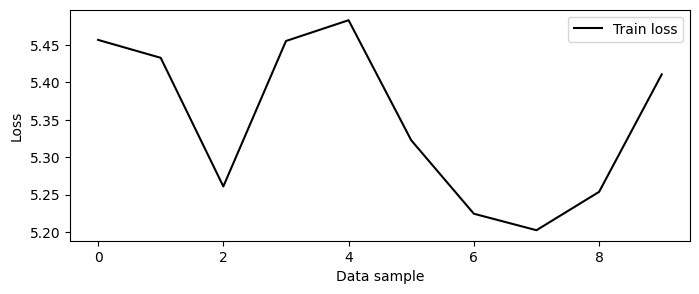

In [11]:
plt.figure(figsize=(8,3))
plt.plot(train_loss,'k',markersize=8,label='Train loss')
plt.legend()
plt.gca().set(xlabel='Data sample',ylabel='Loss')
plt.show()

# Eval

In [12]:
# grab the weight matrices again
frozenW_pst = gpt2.transformer.h[6].mlp.c_fc.weight.data.cpu()
trainW_pst  = gpt2.transformer.ln_f.weight.data.cpu()

In [13]:
# should be all zeros if the layer was frozen
print('Frozen layer, norm(post-pre):')
print('  ', torch.norm(frozenW_pst - frozenW_pre))

print('\n Trainable layer, norm(post-pre)')
print('  ', torch.norm(trainW_pst - trainW_pre))

Frozen layer, norm(post-pre):
   tensor(0.)

 Trainable layer, norm(post-pre)
   tensor(0.0106)


# When, where, and why to freeze?

Why?

* Reduces risk of overfitting idiosyncrasies in small training sets
* Useful with limited data
* Very large LMs (e.g., >10b parameters) can be prohibitively expensive (time, cost, memory) to train the entire model.
* Freezing weights in early transformer blocks preserves basic semantic patterns while training higher-level feature

Where and when to freeze?

* Freeze MLP only and allow attention layers to be adjusted: adjust how the model integrates across tokens
* Freeze early transformer blocks: good for classification
* Freeze early in fine-tuning and unfreeze as the loss drops (less to learn)
* Targeted freezing to test hypotheses in mechanistic interpretability